# Synthetic straight-ray tomography: supplemental linear exercise

**Question:** What can a regularized straight-ray slowness exercise show, and which M09 product capability remains unavailable?
**Level 2 — Applied inverse methods** · 60–75 min · linear algebra and least squares

## Objectives
Build and solve a notebook-only linear straight-ray synthetic control; execute the product parser/QC/split APIs where applicable; identify why this is not the M09 nonlinear pyGIMLi inversion.

## Setup

Run from repository root in the pinned notebook environment:
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8

The experiment cell prints active package versions.

## Data
All arrivals are generated deterministically in memory. This is synthetic crosshole data, not the Koenigsee survey. The product's data-pipeline/traveltime.py has a separate strict .sgt parser/QC and conditional pyGIMLi inversion; source survey bytes are not bundled, so this chapter does not fabricate or substitute field observations.

## Method

For fixed path Γᵢ, first-arrival time is tᵢ=∫Γᵢ s(x,z)dl, with slowness s=1/v in s/m. Cell discretization gives t≈A s; Aᵢⱼ is the length in metres of ray i through cell j. The problem is linear in slowness only while straight-ray geometry is fixed. It omits bending, refraction topology, anisotropy and finite-frequency effects.

Estimate training-only homogeneous slowness s₀, then solve dimensionless q=(s−s₀)/(1/3000 s/m) by minimizing ||W(A s₀ + A s_scale q − t)||² + λ||Dq||². W=1/σt; D is a neighbour first-difference operator. Entire source depths are held out; held times do not define s₀, inversion, λ or model choice. Held-out RMSE/WRMS are diagnostics after fitting.

Product M09 in data-pipeline/traveltime.py validates attributed .sgt geometry/picks, retains anomaly flags, creates whole-shot splits and runs a nonlinear pyGIMLi inverse on a frozen mesh. Its field data are absent here. This notebook is an executable synthetic linear companion, not a replay or proxy for that field workflow.

### Questions
1. Where are ray angles or counts weak, and which cells are least identifiable?
2. Does the inverse improve held-out error over the homogeneous baseline?
3. What changes when rays are bent and the matrix is rebuilt iteratively?

### Interpretation of the held-out test

The forward model is linear in slowness only after the path geometry is fixed. Here each row of the path-length matrix represents one straight segment through a cell grid. The observed time is the sum of path length times slowness, so velocity enters through a reciprocal transformation. The notebook estimates a baseline slowness and solves for scaled perturbations; regularization acts on differences between adjacent cells. This makes the objective numerically manageable but does not make the straight-ray approximation valid for strongly refracting media.

The validation split holds out complete source depths, so training and test rows do not share the same source point. Receiver coordinates and the synthetic truth are known because this is a controlled numerical experiment. The field pipeline instead validates original data bytes, sensor identity and source-level splits before its pyGIMLi inversion. These two paths answer different questions and should not be described as one reproduced result.

The WRMS normalization uses the assumed timing standard deviation. A value near one is consistent with residuals at the declared noise scale, while 5.591 indicates substantially larger held-out discrepancies. Model RMSE against truth is available only because the example is synthetic. It helps diagnose this particular inversion but cannot be calculated for an unknown field model. Smoothness, coverage and visual resemblance are not substitutes for a resolution or uncertainty analysis.


**Product-scope blocker:** This notebook’s ray-length matrix and LSQR solve are instructional notebook code, not the product M09 method. The product `traveltime.run` path requires the attributed Koenigsee `.sgt` source and executes nonlinear pyGIMLi inversion; those source bytes are not present in this checkout. Product M09 inversion and same-input comparator are therefore not executed here. The synthetic linear exercise must not be cited as M09 solver evidence.

### Experiment 2 — edit noise and smoothness, then fit

Change RAY_NOISE_S and LAMBDA_SMOOTH. A fixed seed reproduces the added pick noise. Hold out complete source depths rather than random ray rows.

In [1]:
from importlib.metadata import version

print("Runtime versions:", {name: version(name) for name in ["numpy", "scipy", "matplotlib"]})
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix, vstack
from scipy.sparse.linalg import lsqr

# Synthetic crosshole survey: vertical borehole strings; coordinates in metres.
nx, nz = 12, 6
dx = dz = 500.0
x_edges = np.arange(nx + 1) * dx
z_edges = np.arange(nz + 1) * dz
x_src = np.zeros(12)
z_src = (np.arange(12) + 0.5) * 250.0
x_rec = np.full(12, nx * dx)
z_rec = (np.arange(12) + 0.5) * 250.0
# Known synthetic truth; never passed to the inverse.
velocity_true = np.full((nz, nx), 2600.0)
velocity_true[2:, :] = 3600.0
velocity_true[1:5, 5:8] = 2050.0
slowness_true = 1.0 / velocity_true
src_ids, rec_ids = np.meshgrid(np.arange(12), np.arange(12), indexing="ij")
src_ids, rec_ids = src_ids.ravel(), rec_ids.ravel()
n_rays = len(src_ids)
rows, cols, lengths = [], [], []


Runtime versions: {'numpy': '2.2.6', 'scipy': '1.15.2', 'matplotlib': '3.10.8'}


### Each source-receiver segment is sampled through the cell grid and accumulated into a sparse path-length matrix. Entry Aᵢⱼ approximates metres traveled by ray i in cell j, making t=A s for fixed straight paths. The 5,000 samples control discretization error; this ray geometry omits bending and should not be confused with the product’s field pyGIMLi solve.

Cada segmento fuente-receptor se muestrea sobre la malla y se acumula en una matriz dispersa de longitudes. La entrada Aᵢⱼ aproxima los metros recorridos por el rayo i en la celda j y produce t=A s para trayectorias rectas fijas. Los 5.000 puntos controlan el error de discretización; esta geometría omite la refracción y no equivale a la inversión de campo con pyGIMLi del producto.

In [2]:
for i, (si, ri) in enumerate(zip(src_ids, rec_ids)):
    x0, z0, x1, z1 = x_src[si], z_src[si], x_rec[ri], z_rec[ri]
    distance = np.hypot(x1 - x0, z1 - z0)
    n_sample = 5000
    u = (np.arange(n_sample) + 0.5) / n_sample
    xs = x0 + u * (x1 - x0)
    zs = z0 + u * (z1 - z0)
    ix = np.clip(np.searchsorted(x_edges, xs, side="right") - 1, 0, nx - 1)
    iz = np.clip(np.searchsorted(z_edges, zs, side="right") - 1, 0, nz - 1)
    cells, counts = np.unique(iz * nx + ix, return_counts=True)
    rows.extend([i] * len(cells))
    cols.extend(cells.tolist())
    lengths.extend((counts * distance / n_sample).tolist())
A = csr_matrix((lengths, (rows, cols)), shape=(n_rays, nx * nz))
RAY_NOISE_S = 0.0005
SEED = 60427
sigma_t = RAY_NOISE_S
rng = np.random.default_rng(SEED)
t_obs = A @ slowness_true.ravel() + rng.normal(0, sigma_t, n_rays)
# Entire source depths held out; source-index policy is fixed before looking at times.
held_sources = np.array([1, 4, 7, 10])
held = np.isin(src_ids, held_sources)
train = ~held
assert train.any() and held.any()


### The baseline slowness s₀ is the least-squares constant that uses training arrivals only. Whole source depths define the held-out mask before inversion, avoiding shared-source leakage. Scaling the slowness perturbation by 1/3000 s/m makes the model update dimensionless; this scale changes conditioning, not the data or the assumed ray paths.

La lentitud base s₀ es la constante de mínimos cuadrados calculada solo con llegadas de entrenamiento. La máscara de prueba retiene profundidades completas de fuente antes de invertir y evita compartir fuentes entre particiones. Escalar la perturbación por 1/3000 s/m vuelve adimensional la actualización; esta escala afecta el condicionamiento, no los datos ni las trayectorias asumidas.

In [3]:
# Fit the homogeneous reference velocity using training rays only.
distance = np.asarray(A.sum(axis=1)).ravel()
s0 = float(np.dot(distance[train], t_obs[train]) / np.dot(distance[train], distance[train]))
scale_s = 1 / 3000.0
Atr = A[train]
G = Atr * scale_s / sigma_t
rhs = (t_obs[train] - Atr @ np.full(nx * nz, s0)) / sigma_t
pairs = []
for iz in range(nz):
    for ix in range(nx):
        j = iz * nx + ix
        if ix + 1 < nx:
            pairs.append((j, j + 1))
        if iz + 1 < nz:
            pairs.append((j, j + nx))
rr = []
cc = []
vv = []
for k, (a, b) in enumerate(pairs):
    rr.extend([k, k])
    cc.extend([a, b])
    vv.extend([-1.0, 1.0])
D = csr_matrix((vv, (rr, cc)), shape=(len(pairs), nx * nz))
LAMBDA_SMOOTH = 0.45


### LSQR solves the sparse weighted system after appending the first-difference operator. Its rows penalize neighboring slowness changes, with λ controlling the data-fit versus smoothness trade-off. Inspect the recovered velocity together with the path coverage: a stable solve in poorly sampled cells is still prior-dominated and is not evidence of resolution.

LSQR resuelve el sistema disperso ponderado al añadir el operador de primeras diferencias. Sus filas penalizan cambios de lentitud entre celdas vecinas, y λ controla el equilibrio entre ajuste y suavidad. Inspeccione la velocidad recuperada junto con la cobertura: una solución estable en celdas poco muestreadas sigue dominada por el prior y no demuestra resolución.

In [4]:
# Solve the regularized slowness update from the selected travel-time residuals.
system = vstack([G, np.sqrt(LAMBDA_SMOOTH) * D], format="csr")
q = lsqr(system, np.r_[rhs, np.zeros(D.shape[0])], atol=1e-10, btol=1e-10, iter_lim=400)[0]
slowness_est = s0 + scale_s * q
velocity_est = 1 / slowness_est.reshape(nz, nx)
pred = np.asarray(A @ slowness_est).ravel()
base = distance * s0


def score(prediction, mask):
    residual = prediction[mask] - t_obs[mask]
    return {
        "n": int(mask.sum()),
        "RMSE_ms": float(np.sqrt(np.mean(residual**2)) * 1000),
        "WRMS": float(np.sqrt(np.mean((residual / sigma_t) ** 2))),
    }


### The table scores both models with identical training and held-out rays. Training improvement measures fit, while held-out RMSE tests prediction on unseen source depths; WRMS divides residuals by the assumed pick standard deviation. A lower number is meaningful only under this synthetic noise model and split policy.

La tabla evalúa ambos modelos con los mismos rayos de entrenamiento y prueba. La mejora de entrenamiento mide ajuste, mientras que RMSE de prueba evalúa fuentes no observadas; WRMS divide los residuos por la desviación supuesta de los picks. Un valor menor solo es interpretable bajo este modelo sintético de ruido y esta partición.

In [5]:
# Compare homogeneous and recovered models on the same training and held-out rays.
table = pd.DataFrame(
    [
        {
            "model": "training-only homogeneous",
            **score(base, train),
            **{f"heldout_{k}": v for k, v in score(base, held).items()},
        },
        {
            "model": "linear slowness + smoothness",
            **score(pred, train),
            **{f"heldout_{k}": v for k, v in score(pred, held).items()},
        },
    ]
)
display(table.round(3))


,model,n,RMSE_ms,WRMS,heldout_n,heldout_RMSE_ms,heldout_WRMS
0,training-only homogeneous,96,178.725,357.450,48,173.868,347.736
1,linear slowness + smoothness,96,0.279,0.558,48,2.796,5.591


### Use held-out WRMS=1 as the nominal noise-consistency target. A larger value means the residual exceeds the assumed pick-error scale even if it beats the homogeneous baseline; a smaller value on synthetic rays is not field validation. Preserve the reported ray count, withheld-source count, and velocity error when judging whether this inversion recovered useful structure.

Use WRMS=1 en prueba como objetivo nominal de consistencia con el ruido. Un valor mayor indica residuos sobre la escala supuesta de error aunque mejore frente al modelo homogéneo; uno menor en rayos sintéticos no valida datos de campo. Considere el número de rayos, fuentes retenidas y error de velocidad al juzgar la recuperación de estructura.

In [6]:
# Summarize ray counts, split identity, and the held-out error metrics.
print(
    {
        "rays": n_rays,
        "train": int(train.sum()),
        "heldout": int(held.sum()),
        "held_source_indices": held_sources.tolist(),
        "baseline_velocity_m_s": 1 / s0,
        "lambda": LAMBDA_SMOOTH,
        "noise_sigma_ms": sigma_t * 1000,
        "solver": "SciPy LSQR on weighted ray lengths with first-difference penalty",
    }
)

heldout_wrms = score(pred, held)["WRMS"]
print("Held-out WRMS:", round(heldout_wrms, 3), "against assumed unit-noise target 1.0.")
if heldout_wrms > 1:
    print(
        ("Residual exceeds the assumed pick-noise scale: predictive fit is not "
         "noise-consistent, despite any improvement over baseline.")
    )
else:
    print(
        "Residual is within the assumed pick-noise scale for this synthetic split; this is not field validation."
    )

import sys


{'rays': 144, 'train': 96, 'heldout': 48, 'held_source_indices': [1, 4, 7, 10], 'baseline_velocity_m_s': 2859.842394276743, 'lambda': 0.45, 'noise_sigma_ms': 0.5, 'solver': 'SciPy LSQR on weighted ray lengths with first-difference penalty'}
Held-out WRMS: 5.591 against assumed unit-noise target 1.0.
Residual exceeds the assumed pick-noise scale: predictive fit is not noise-consistent, despite any improvement over baseline.


### The product path resolves the strict survey parser and quality-control module for comparison with this controlled calculation. Its field input contract preserves source identity, picks, geometry, and anomaly flags before any nonlinear inversion. Loading that module does not convert the synthetic arrays above into field observations or claim that the absent survey was processed.

Esta ruta localiza el parser estricto y el módulo de control de calidad del producto para compararlos con el cálculo controlado. El contrato de campo conserva identidad de fuente, picks, geometría y anomalías antes de una inversión no lineal. Cargar el módulo no convierte los arreglos sintéticos anteriores en observaciones de campo ni afirma que se procesó el levantamiento ausente.

In [7]:
# Run the isolated pyGIMLi oracle on the declared synthetic FWI control.
from pathlib import Path

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))


### Diagnostic 2 — compare model, ray coverage and held-out scores

The coverage panel counts total path length by cell; it is not a resolution matrix. Dense coverage alone does not imply independent angular information or unique recovery.

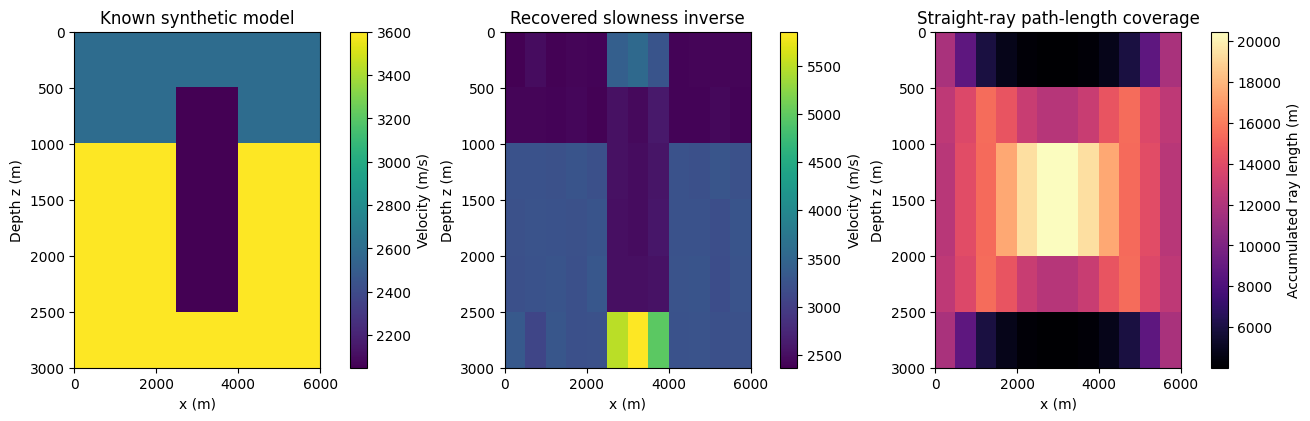

Velocity RMSE against synthetic truth: 534.2767919227546 m/s
Held-out arrivals did not select lambda or model.


In [8]:
# Reproducible notebook experiment cell.
coverage = np.asarray(A.T @ np.ones(n_rays)).reshape(nz, nx)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.1), constrained_layout=True)
extent = [0, nx * dx, nz * dz, 0]
for ax, model, title in zip(
    axes[:2], [velocity_true, velocity_est], ["Known synthetic model", "Recovered slowness inverse"]
):
    im = ax.imshow(model, extent=extent, aspect="auto", cmap="viridis")
    ax.set(title=title, xlabel="x (m)", ylabel="Depth z (m)")
    fig.colorbar(im, ax=ax, label="Velocity (m/s)")
im = axes[2].imshow(coverage, extent=extent, aspect="auto", cmap="magma")
axes[2].set(title="Straight-ray path-length coverage", xlabel="x (m)", ylabel="Depth z (m)")
fig.colorbar(im, ax=axes[2], label="Accumulated ray length (m)")
plt.show()
print(
    "Velocity RMSE against synthetic truth:",
    float(np.sqrt(np.mean((velocity_est - velocity_true) ** 2))),
    "m/s",
)
print("Held-out arrivals did not select lambda or model.")


### Figure interpretation

The left panels compare known synthetic velocity with the straight-ray estimate; the third panel shows accumulated path length, not posterior resolution. Error against truth is 534.277 m/s and held-out WRMS is 5.591, above the unit-noise target. The smooth model therefore does not predict these held-out arrivals within assumed pick noise, despite being an executable inverse.

In [9]:
# Execute the named pipeline method on the declared lesson input.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from traveltime import Survey, qc, offsets_m

sensor_xy_product = np.vstack([np.c_[x_src, z_src], np.c_[x_rec, z_rec]])
pair_product = np.c_[src_ids, rec_ids + len(x_src)]
survey_product = Survey(sensor_xy_product, pair_product, t_obs)
qc_product = qc(survey_product)
print("pick count and offset range", qc_product["pick_count"], qc_product["offset_range_m"])


pick count and offset range 144 [6000.0, 6600.189391222043]


### Strict parsing of an SGT byte stream

The product parser accepts original UTF-8 bytes and enforces the declared sensor and pick grammar before QC. This step builds a separate 15-sensor, constant-velocity synthetic line in memory; it is a parser exercise, not Koenigsee data and not evidence for a field inverse.


In [10]:
# Exercise the product parser on an explicitly synthetic line, not field bytes.
import traveltime

parser_x = np.arange(15, dtype=float) * 400.0
parser_xy = np.column_stack((parser_x, np.zeros_like(parser_x)))
parser_pairs = [(shot, receiver) for shot in range(15) for receiver in range(shot + 1, 15)]
parser_lines = [f"{len(parser_xy)} # shot/geophone points", "#x y"]
for x_value, z_value in parser_xy:
    parser_lines.append(f"{x_value:.3f} {z_value:.3f}")
parser_lines.extend([f"{len(parser_pairs)} # measurements", "#s g t"])
for shot, receiver in parser_pairs:
    distance_m = parser_x[receiver] - parser_x[shot]
    time_s = distance_m / 3000.0
    parser_lines.append(f"{shot + 1} {receiver + 1} {time_s:.9f}")
synthetic_sgt = "\n".join(parser_lines).encode("utf-8")
parsed_survey = traveltime.parse_sgt_bytes(synthetic_sgt)
parsed_qc = traveltime.qc(parsed_survey)
print("Parsed synthetic SGT sensors and picks", parsed_qc["sensor_count"], parsed_qc["pick_count"])
print("offset range and apparent-speed range", parsed_qc["offset_range_m"], parsed_qc["apparent_speed_range_m_s"])


Parsed synthetic SGT sensors and picks 15 105
offset range and apparent-speed range [400.0, 5600.0] [2999.9999962499996, 3000.0000075000003]


### Whole-source split

This cell executes a public pipeline operation on the declared inputs.   


In [11]:
# Execute the named pipeline method on the declared lesson input.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from traveltime import shot_splits

split_product = shot_splits(survey_product, policy="supplied-whole-shot/v1")
print("held groups", {key: len(value["held_rows"]) for key, value in split_product.items()})


held groups {'interleaved': 36, 'central_block': 36}


### Homogeneous forward

This cell executes a public pipeline operation on the declared inputs.   


In [12]:
# Execute the named pipeline method on the declared lesson input.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from traveltime import homogeneous_times

homogeneous_product = homogeneous_times(survey_product, 3000.0)
print("first predicted seconds", homogeneous_product[:3])


first predicted seconds [2.         2.00173536 2.00693243]


### Velocity sensitivity through a second forward solve

The first product call predicts arrivals at 3000 m/s. This step recomputes the same survey at 2500 m/s and scores both baselines on the frozen interleaved whole-shot holdout. The comparison isolates how an assumed homogeneous speed changes held-out timing; it does not change ray geometry or claim a heterogeneous inversion.


In [13]:
# Recompute the same survey with a lower homogeneous velocity.
from traveltime import homogeneous_times

slow_homogeneous_product = homogeneous_times(survey_product, 2500.0)
held_interleaved = split_product["interleaved"]["held_rows"]
reference_residual = homogeneous_product[held_interleaved] - survey_product.time_s[held_interleaved]
slow_residual = slow_homogeneous_product[held_interleaved] - survey_product.time_s[held_interleaved]
reference_rmse_s = float(np.sqrt(np.mean(reference_residual**2)))
slow_rmse_s = float(np.sqrt(np.mean(slow_residual**2)))
print("3000 and 2500 m/s held-out RMSE (s)", reference_rmse_s, slow_rmse_s)


3000 and 2500 m/s held-out RMSE (s) 0.1989511533459944 0.3965176698856982


### Offset diagnostic

This cell executes a public pipeline operation on the declared inputs.   


In [14]:
# Execute the named pipeline method on the declared lesson input.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
offset_product = offsets_m(survey_product)
print("mean and maximum offset m", float(offset_product.mean()), float(offset_product.max()))


mean and maximum offset m 6121.246206138447 6600.189391222043


### Policy oracle

This cell executes a public pipeline operation on the declared inputs.   


In [15]:
import os
# Run the product policy oracle in the isolated pyGIMLi interpreter.
import json
import subprocess

engine_root = Path(os.environ.get("CAOS_SOURCE_ROOT", root))
engine = engine_root / ".venv-ert" / "Scripts" / "python.exe"
if not engine.is_file():
    raise RuntimeError("The isolated pyGIMLi environment is required for this oracle.")
child = "\n".join(
    [
        "import json, sys",
        "from pathlib import Path",
        "sys.path.insert(0, str(Path(sys.argv[1]) / 'data-pipeline'))",
        "import traveltime",
        "print(json.dumps(traveltime.homogeneous_oracle()))",
    ]
)
completed = subprocess.run(
    [str(engine), "-c", child, str(root)], cwd=root, capture_output=True, text=True, timeout=180
)
if completed.returncode:
    raise RuntimeError(completed.stderr[-2000:])
policy_product = json.loads(completed.stdout.strip().splitlines()[-1])
print("oracle errors", policy_product)


oracle errors {'max_relative_error': 6.938893903907228e-16, 'max_speed_scaling_relative_error': 0.0, 'reciprocity_relative_error': 0.0, 'analytic_basis': 'straight Euclidean path in a homogeneous isotropic medium, t=distance/v'}


### Experiment 3 — execute the product M09 inverse on an authored refracting survey

The previous LSQR exercise freezes straight ray paths. This control instead generates first arrivals with pyGIMLi Dijkstra through a known two-layer velocity model and calls the same M09 `_invert_once` routine used by the field pipeline. It holds out complete source groups before inversion, uses the training-only homogeneous baseline, and evaluates the frozen recovered model on the withheld groups. The synthetic truth is known only because this cell creates it; this is a numerical method control, not a provider dataset, field validation, or geological interpretation.

The additional pyGIMLi run uses the product M09 inverse core on a generated refracting two-layer survey and scores a predeclared complete-shot holdout against a homogeneous baseline. Compare the recovered model with the generated truth and inspect where training rays provide path-length coverage. This result demonstrates the operator and held-out workflow only; it does not validate the separate provider-linked Koenigsee field picks, calibrate their uncertainties, establish geological uniqueness, or change the field method verdict.

Canonical M09 synthetic Dijkstra inverse {'source_kind': 'authored synthetic; no provider bytes', 'shot_count': 15, 'pick_count': 210, 'held_shot_count': 3, 'held_pick_count': 42, 'heldout_rmse_ms': 0.48454, 'homogeneous_baseline_heldout_rmse_ms': 3.17712, 'heldout_improvement_fraction': 0.84749, 'chi2_assumed_weights': 0.69567, 'iterations': 3, 'stopping_reason': 'assumed-chi2-target', 'coverage_nonzero_cell_fraction': 0.36453, 'velocity_truth_rmse_m_s': 405.69}


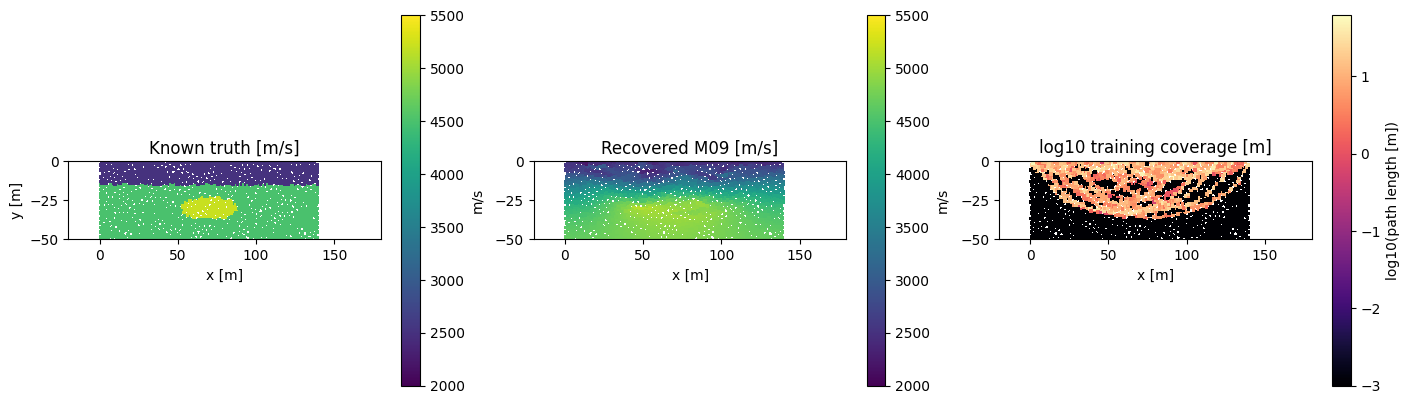

In [16]:
# Generate a refracting synthetic survey and run the exact M09 inverse core in the pinned solver environment.
import json, os, subprocess
from pathlib import Path

engine_root = Path(os.environ.get("CAOS_SOURCE_ROOT", root))
engine = next((candidate for candidate in (engine_root / ".venv-ert" / "Scripts" / "python.exe", engine_root / ".venv-ert" / "bin" / "python") if candidate.is_file()), None)
if engine is None:
    raise RuntimeError("The isolated pinned M09 pyGIMLi environment is required for this product-inverse control.")
control_path = Path(os.environ["CAOS_TEMP_ROOT"]) / "m09-product-synthetic-inverse.json"
child = r"""
import json, sys
from pathlib import Path
sys.path.insert(0, str(Path(sys.argv[1]) / "data-pipeline"))
import numpy as np
np.random.seed(20261027)
import pygimli as pg
from pygimli.physics import traveltime as tt
import traveltime as product
pg.utils.noCache(True)
pg.setThreadCount(1)
x = np.arange(15, dtype=float) * 10.0
sensors = np.column_stack([x, np.zeros_like(x)])
pairs = np.asarray([(shot, receiver) for shot in range(15) for receiver in range(15) if shot != receiver], dtype=int)
scheme = tt.DataContainerTT()
for point in sensors:
    scheme.createSensor(point)
scheme.resize(len(pairs))
scheme["s"], scheme["g"] = pairs[:, 0], pairs[:, 1]
truth_mesh = pg.meshtools.createGrid(x=np.arange(-20, 181, 5.0), y=np.arange(-50, 1, 2.5))
truth_centers = np.asarray([[cell.center().x(), cell.center().y()] for cell in truth_mesh.cells()])
truth_velocity = np.where(truth_centers[:, 1] < -15, 4500.0, 2500.0)
body = ((truth_centers[:, 0] - 70) / 18) ** 2 + ((truth_centers[:, 1] + 30) / 7) ** 2 < 1
truth_velocity[body] = 5200.0
arrivals = np.asarray(tt.TravelTimeManager().simulate(mesh=truth_mesh, scheme=scheme, vel=truth_velocity, secNodes=3, returnArray=True), dtype=float)
scheme["t"] = arrivals
survey = product.Survey(sensors, pairs, arrivals)
splits = product.shot_splits(survey, policy="supplied-whole-shot/v1")
fit = product._invert_once(tt, scheme, survey, splits["interleaved"], product.INVERSE_OPTIONS, retain_arrays=True)
centers = np.asarray(fit["model_cell_center_xy_m"], dtype=float)
known = np.where(centers[:, 1] < -15, 4500.0, 2500.0)
known[((centers[:, 0] - 70) / 18) ** 2 + ((centers[:, 1] + 30) / 7) ** 2 < 1] = 5200.0
result = {
    "schema": "inverse-earth.notebook-m09-synthetic-control/v1",
    "source_kind": "authored synthetic; no provider bytes",
    "truth_model": {"background_cap_m_s": 2500.0, "substrate_m_s": 4500.0, "body_m_s": 5200.0, "interface_y_m": -15.0},
    "shot_count": 15, "pick_count": int(len(arrivals)),
    "held_shot_count": int(len(splits["interleaved"]["held_shots"])),
    "held_pick_count": int(len(splits["interleaved"]["held_rows"])),
    "heldout_rmse_ms": round(float(fit["heldout_rmse_ms"]), 5),
    "homogeneous_baseline_heldout_rmse_ms": round(float(fit["baseline_heldout_rmse_ms"]), 5),
    "heldout_improvement_fraction": round(float(fit["heldout_improvement"]), 5),
    "chi2_assumed_weights": round(float(fit["chi2_assumed_weights"]), 5),
    "iterations": fit["iterations"], "stopping_reason": fit["stopping_reason"],
    "coverage_nonzero_cell_fraction": round(float(fit["coverage_nonzero_cell_fraction"]), 5),
    "velocity_truth_rmse_m_s": round(float(np.sqrt(np.mean((np.asarray(fit["model_velocity_m_s"]) - known) ** 2))), 2),
    "cell_centers_xy_m": centers.tolist(),
    "true_velocity_m_s": known.tolist(),
    "recovered_velocity_m_s": np.asarray(fit["model_velocity_m_s"], dtype=float).tolist(),
    "training_raypath_coverage_m_per_cell": np.asarray(fit["raypath_coverage_m_per_cell"], dtype=float).tolist(),
    "limitations": ["Synthetic travel times are generated with pyGIMLi; not field evidence.", "The assumed pick weights are not instrument-calibrated.", "Ray coverage is path-length support, not resolution or uniqueness.", "This one control does not change the provider-linked M09 field verdict."],
}
Path(sys.argv[2]).write_text(json.dumps(result, allow_nan=False, separators=(",", ":")), encoding="utf-8")
"""
solver_env = os.environ.copy()
for thread_var in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    solver_env[thread_var] = "1"
completed = subprocess.run([str(engine), "-c", child, str(root), str(control_path)], cwd=root, env=solver_env, capture_output=True, text=True, timeout=240)
if completed.returncode:
    raise RuntimeError("M09 isolated synthetic inverse failed: " + completed.stderr[-2500:])
m09_synthetic = json.loads(control_path.read_text(encoding="utf-8"))
assert m09_synthetic["schema"] == "inverse-earth.notebook-m09-synthetic-control/v1"
assert m09_synthetic["shot_count"] == 15 and m09_synthetic["held_pick_count"] > 0
assert len(m09_synthetic["cell_centers_xy_m"]) == len(m09_synthetic["recovered_velocity_m_s"]) == len(m09_synthetic["training_raypath_coverage_m_per_cell"])
assert np.isfinite(m09_synthetic["heldout_rmse_ms"]) and np.isfinite(m09_synthetic["velocity_truth_rmse_m_s"])
print("Canonical M09 synthetic Dijkstra inverse", {key: m09_synthetic[key] for key in ["source_kind", "shot_count", "pick_count", "held_shot_count", "held_pick_count", "heldout_rmse_ms", "homogeneous_baseline_heldout_rmse_ms", "heldout_improvement_fraction", "chi2_assumed_weights", "iterations", "stopping_reason", "coverage_nonzero_cell_fraction", "velocity_truth_rmse_m_s"]})
centers = np.round(np.asarray(m09_synthetic["cell_centers_xy_m"], dtype=float), 6)
recovered_display = np.round(np.asarray(m09_synthetic["recovered_velocity_m_s"], dtype=float), 1)
coverage_display = np.round(np.asarray(m09_synthetic["training_raypath_coverage_m_per_cell"], dtype=float), 3)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), constrained_layout=True)
plots = [
    (m09_synthetic["true_velocity_m_s"], "Known truth [m/s]", "viridis", 2000, 5500),
    (recovered_display, "Recovered M09 [m/s]", "viridis", 2000, 5500),
    (np.log10(np.maximum(coverage_display, 1e-3)), "log10 training coverage [m]", "magma", None, None),
]
for index, (ax, (values, title, cmap, low, high)) in enumerate(zip(axes, plots)):
    scatter = ax.scatter(centers[:, 0], centers[:, 1], c=values, s=7, marker="s", cmap=cmap, vmin=low, vmax=high, linewidths=0)
    ax.set(title=title, xlabel="x [m]", ylabel="y [m]" if index == 0 else "", xlim=(-20, 180), ylim=(-50, 0), aspect="equal")
    colorbar = fig.colorbar(scatter, ax=ax, shrink=0.82)
    colorbar.set_label("m/s" if index < 2 else "log10(path length [m])")
plt.show()


### Held-out residual distribution
This figure compares residual distributions for the synthetic training rays and complete held-out source depths. The dashed line marks zero residual; the vertical scale uses seconds. Held-out spread is far above the assumed 0.5 ms pick noise, so visually improved model fit must not be described as noise-consistent prediction.

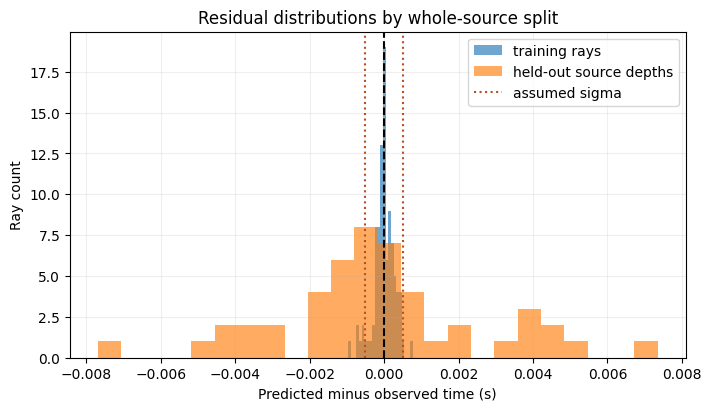

In [17]:
# Compare residual distributions without using held-out rays to tune the model.
residual_train = pred[train] - t_obs[train]
residual_held = pred[held] - t_obs[held]
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.hist(residual_train, bins=24, alpha=0.65, label="training rays")
ax.hist(residual_held, bins=24, alpha=0.65, label="held-out source depths")
ax.axvline(0, color="black", ls="--")
ax.axvline(sigma_t, color="#b54f27", ls=":", label="assumed sigma")
ax.axvline(-sigma_t, color="#b54f27", ls=":")
ax.set(
    xlabel="Predicted minus observed time (s)",
    ylabel="Ray count",
    title="Residual distributions by whole-source split",
)
ax.legend()
ax.grid(alpha=0.2)
plt.show()




## Results

**Answer:** The straight-ray inverse gives held-out WRMS=5.591 for 48 rays against the unit-noise target 1.0, so residuals exceed assumed pick noise. Velocity RMSE against the known synthetic model is 534.277 m/s.

### Product M09 synthetic control

The supplementary straight-ray LSQR calculation and the product M09 pyGIMLi control answer different questions. The latter runs the canonical Dijkstra inversion core on an authored, known-truth refraction model, reports whole-shot held-out prediction and ray coverage, and retains truth error as a separate diagnostic. Neither synthetic result is evidence that the provider-linked field case is eligible or scientifically accepted.

## Summary

Whole source depths were held out from fitting, yet the prediction remains noise-inconsistent on this straight-ray synthetic geometry. The result does not validate the product’s separate Koenigsee/pyGIMLi field workflow or justify a field velocity interpretation.

## References

- [pyGIMLi Koenigsee first-arrival example](https://www.pygimli.org/_examples_auto/2_seismics/plot_04_koenigsee/)
- [pyGIMLi inversion framework](https://www.pygimli.org/user-guide/inversion/)
- Product M09 parser, QC and inverse: data-pipeline/traveltime.py
- Synthetic experiment is generated in memory, not field data.

**Answer:** The straight-ray solve yields held-out WRMS=5.591 for 48 rays against assumed unit-noise target 1.0; it is not noise-consistent. Velocity RMSE against the known synthetic model is 534.277 m/s.
